In [60]:
from anemone.forwards import *
import torch

In [149]:
def intMat(t_in, t_out):
    t_out = t_out.to(t_in.dtype)
    logT = torch.log(t_in)#.cpu()
    dT = logT[1]-logT[0]
    t2t = torch.nan_to_num(lamontagne((torch.log(t_out)[:,None]-logT[None,:])/dT))
    return t2t

class ForwardLaplace4(ForwardLaplace):
    geomz = None
    t2t   = None
    lmbInt = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None, t_smp_per_decade=10):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance, t_smp_per_decade)
        self.t2t = wv_to_t(self.times, self.t_eval, waveform=self.waveform)#.to_sparse()

    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, ::2, None]
            self.lmbInt = intMat(wave_length[::2], wave_length)

            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.omega = -1j*s[None, None, :]

                
                if self.tmp_u0 is None: self.tmp_u0 = u0(self.omega, self.lmb)
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz)*self.lmb**2 / self.tmp_u0 / c.fourpi
                if self.pfield is None: self.pfield = (torch.exp(-self.tmp_u0*self.pfield_dz)*self.lmb**2 / self.tmp_u0 / c.fourpi)
                self.rte = rte(self.sigma, self.thick, self.omega, self.lmb)
                intg = self.pfield +  self.rte*self.sfield_rte

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                if self.waveform is not None:
                    intg /= -1j*self.omega
                return torch.squeeze(intg).real

            res = invLaplace(s_integrand, device=self.device, n_coefficients=8)(self.t_eval).swapaxes(-2,-1)

            return torch.einsum('ij,...kj->...ki', self.lmbInt, res)

        hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance, smp_per_decade=10)
        r,HR = hkl1.range(self.rmin, self.rmax)
        if self.geomz is None:
            self.geomz = self.source.geomz(self.receiver, r).to(torch.double)
            self.r=r
        else:
            assert torch.all(self.r==r)
        Ht = torch.einsum('...ik,...jk',  self.geomz, HR)

        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', Ht, self.t2t).mT.squeeze()
        else:
            return torch.einsum('...ik,...jk->...ij', Ht, self.t2t).squeeze()   

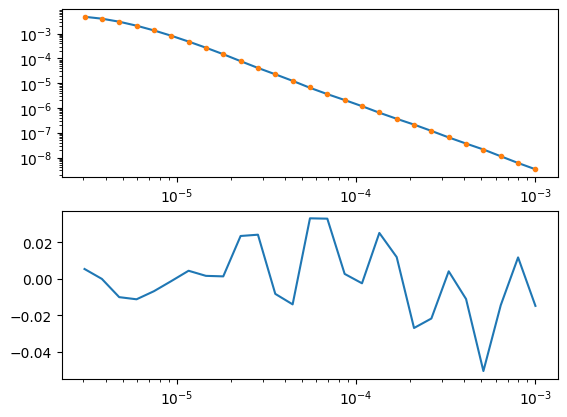

In [150]:
fwr = ForwardLaplace4.example()
fwr0 = ForwardLaplace3.example()
rho = torch.tensor([20, 50, 80]*10)
thk = torch.ones(len(rho)-1)*10
dbdt = fwr(rho, thk)
dbdt0 = fwr0(rho, thk)

import matplotlib.pyplot as plt
import numpy as np

fig,axs = plt.subplots(2,1)
axs[0].loglog(fwr.times, dbdt0, '-')
axs[0].loglog(fwr.times, dbdt, '.')
axs[1].semilogx(fwr.times, (dbdt-dbdt0)/dbdt0, '-')

In [147]:
%%timeit
dbdt = fwr(rho, thk)

90 ms ± 5.5 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [148]:
%%timeit
dbdt0 = fwr0(rho, thk)

232 ms ± 9.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [51]:
lmb2 = lmb[::4]
lmbOut = lmb[1::2]
rtetrue = rte[1::2, 0]
rte0 = rte[::4, 0]

In [53]:
t2t = wv_to_t(lmbOut, lmb2)

In [54]:
rteI = (t2t @ rte0.real) + 1j* (t2t @ rte0.imag)

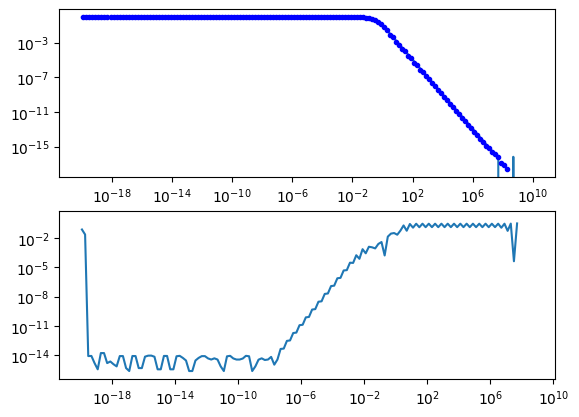

In [57]:
lmb = fwr.lmb.squeeze()
rte = fwr.rte.squeeze()

fig,axs = plt.subplots(2,1)
axs[0].loglog(lmb, torch.abs(rte[:, 0]))
# axs[0].loglog(lmb2, torch.abs(rte0), '.')
axs[0].loglog(lmbOut, torch.abs(rteI), 'b.')
axs[1].loglog(lmbOut, torch.abs((rteI-rtetrue))/torch.abs(rtetrue))

In [18]:
fwr.omega.shape

torch.Size([1, 1, 280])